# Workshop 4 — Reconstruction Quality and Anomaly Detection

This evaluation uses the real embeddings in `data/gold` and the existing AE/VAE checkpoints. Tables come from `runs/workshop4/evaluation/metrics.json`. All six figures are **embedded in this notebook** and can be viewed without executing cells or accessing external image paths. Data augmentation is a separate experiment.

The optional cells at the end allow evaluation to be rerun and updated results to be inspected. Embedded tables and figures represent the saved evaluation run and must be refreshed if models or data change.

## Evaluation Protocol

- Test set: **6,395 reviews**, comprising 5,085 positive, 766 neutral, and 544 negative reviews.
- Normal: positive; anomaly: negative or neutral (**1,310 cases**).
- Input: 768 components standardized using the saved scaler, fitted on 29,842 training examples.
- The checkpoints use **32 latent dimensions**; the README describes a default of 64.
- Inference uses `eval()` with dropout disabled; the VAE reconstructs from μ.
- MSE and Pearson correlation are calculated per example, then aggregated overall and by sentiment.
- Each detector has its own threshold: the 95th percentile of positive validation scores. A review is classified as anomalous when its score exceeds the threshold.
- AUC is computed from continuous test scores. MSE + KL uses KL averaged over latent dimensions, without multiplying it by β.

**Note:** the reconstruction objective does not use labels, but the transformer producing the input embeddings was trained with supervision. According to `train_ae.py`, the models are expected to have been trained only on positive reviews; the exact checkpoint provenance should be confirmed with the team.

## Reconstruction Quality

| Model | Overall MSE ↓ | Pearson ↑ | Positive MSE | Neutral MSE | Negative MSE |
|---|---:|---:|---:|---:|---:|
| ae | 0.2332 | 0.8603 | 0.1880 | 0.3356 | 0.5116 |
| vae_b0.5 | 0.3805 | 0.7417 | 0.3233 | 0.4955 | 0.7536 |
| vae_b1.0 | 0.3975 | 0.7211 | 0.3453 | 0.5081 | 0.7294 |
| vae_b4.0 | 0.5026 | 0.6442 | 0.4255 | 0.6461 | 1.0204 |

The AE achieves the lowest overall MSE and the highest mean correlation. VAE β=0.5 is selected for the panels because it has the lowest **validation MSE** among the VAEs (0.3735). In the available checkpoints, increasing β worsens overall reconstruction. Multiple training seeds were not evaluated.

## Nine Sample Reconstruction Panels

Three examples per sentiment are selected near the 10th, 50th, and 90th percentiles of AE MSE within each class. Each row shows the standardized original, AE reconstruction, VAE β=0.5 reconstruction, and absolute differences. The same examples are used for both models. Bands represent embedding components rather than reconstructed text. Shared color scales support comparison.

Original row identifiers: 32342, 42279, 19697, 35455, 18003, 32518, 12145, 28357, 33695.

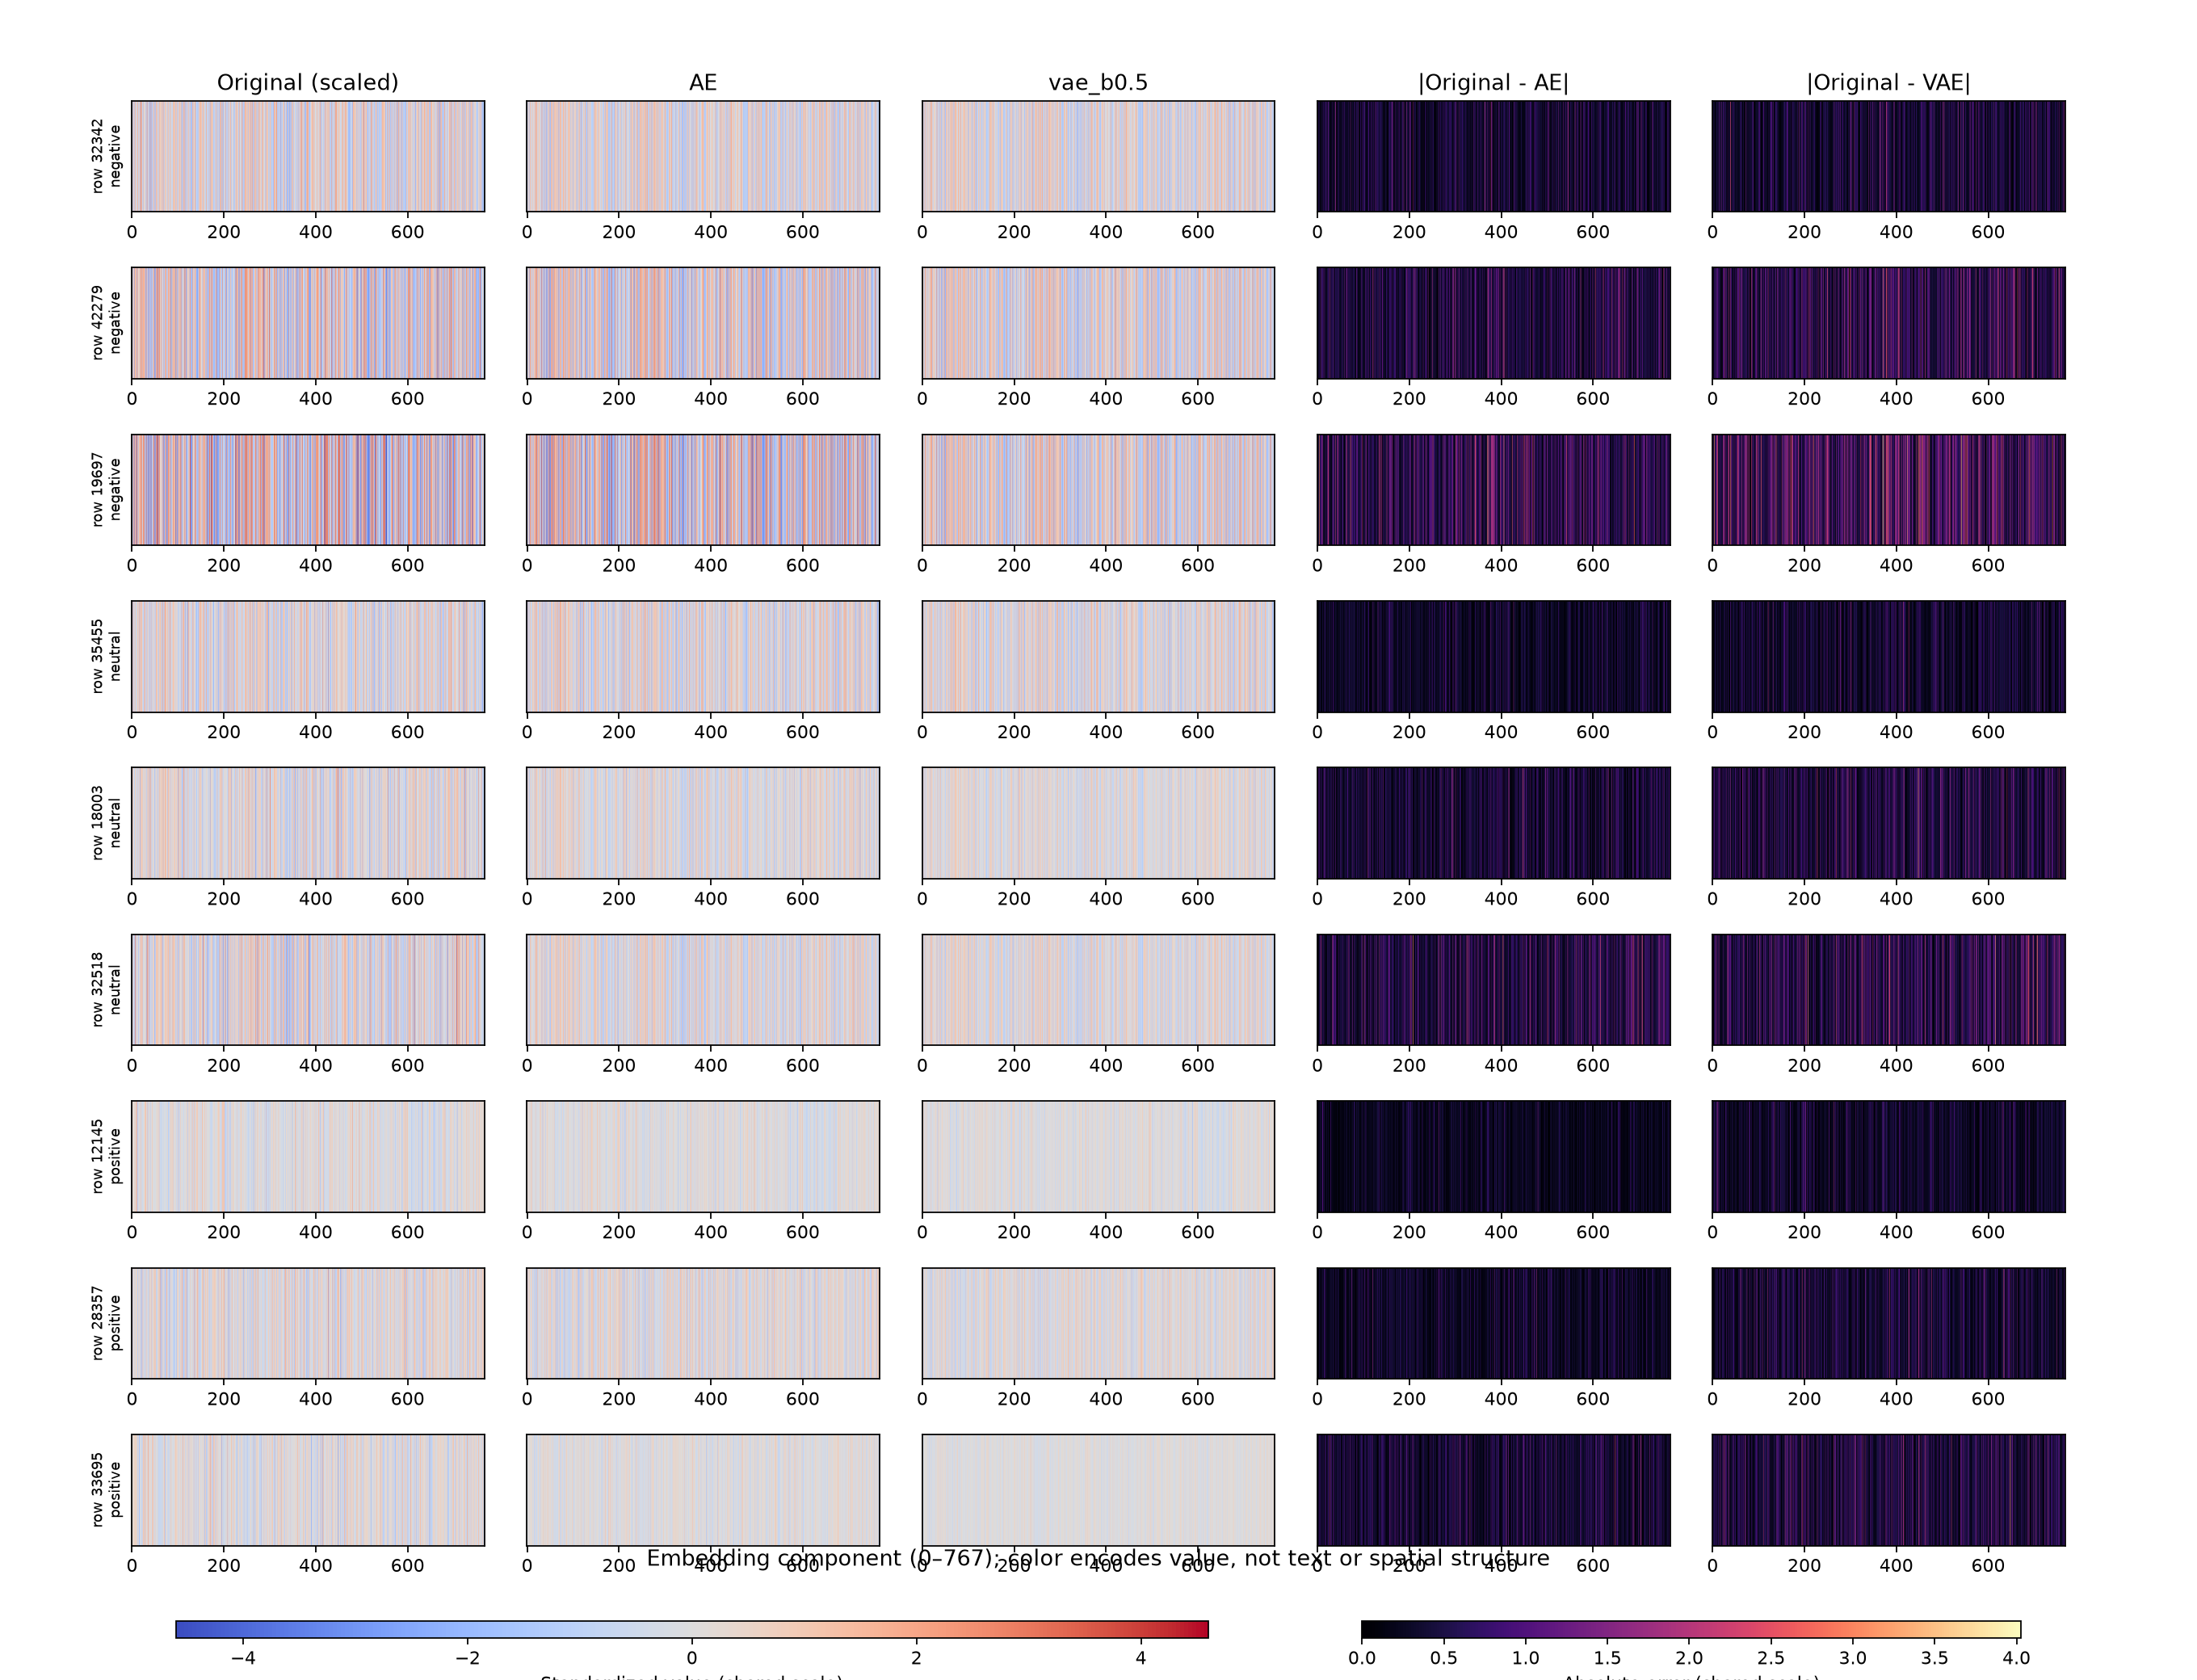

## Which Classes Are Hardest to Reconstruct?

Negative reviews have the highest average MSE, followed by neutral and positive reviews, consistent with training on positive reviews. Variation within classes means that a high score does not identify anomalies perfectly. Pearson correlation and MSE measure different properties: high correlation can coexist with scale or offset errors. The following section links the samples to their recovered original text; these examples support qualitative observations rather than causal explanations.

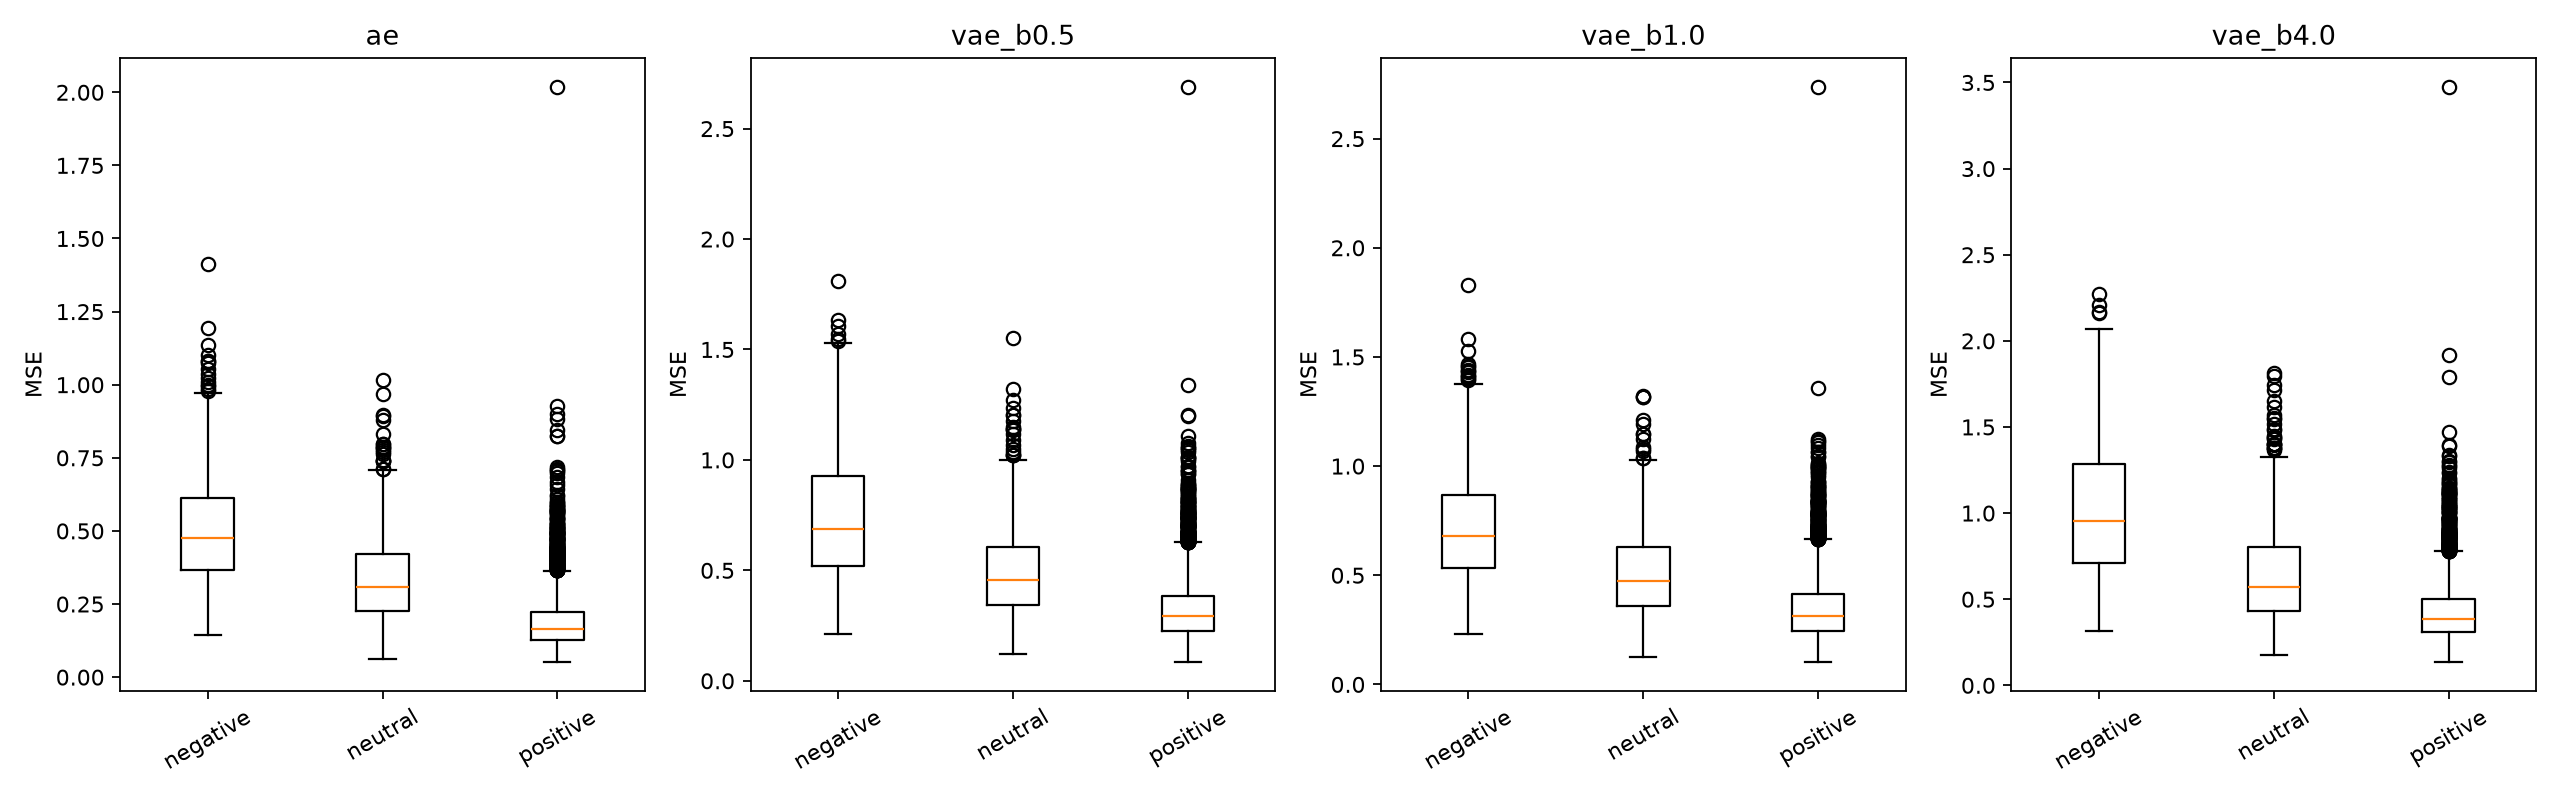

## Original Text of the Reconstruction Samples

The original corpus has now been recovered and its checksum, full label sequence, and frozen split order have been verified. The examples below link the reconstruction panels to their original review content. Excerpts are shortened for readability. They illustrate individual cases and do not establish causes of reconstruction error.

| Row ID | Sentiment | AE MSE | VAE β=0.5 MSE | Original review excerpt |
|---|---|---:|---:|---|
| 32342 | negative | 0.2905 | 0.3353 | The parks are too overcrowded which unfortunately means you spend the majority of the day in queues. You can only fit in a small number of rides a day due to the waiting time. Fast passes are not always available and eve… |
| 42279 | negative | 0.4759 | 0.7460 | We booked this trip for my son's 5th birthday, we stayed in the Sequoia Lodge for 3 nights 4 days. On arrival check in was smooth and we went straight to our room to feed me one year old daughter, there was no kettle in … |
| 19697 | negative | 0.8024 | 1.2872 | We recently visited Disneyland for the day and it was the worst decision of my life. So many attractions were closed, the wait times all 45 , so crowded and I just don't think it had the Disney vibe. No characters were o… |
| 35455 | neutral | 0.1662 | 0.2332 | I must admit I haven't been for a number of years and last time I was there the cast members were very rude. I'm glad to say that's changed now and they were engaging with both my 2 and 12 year olds. However the atmosphe… |
| 18003 | neutral | 0.3069 | 0.4714 | Disney is an incredible place, however the 60th anniversary brought very very long waits and way too many attractions broke down on our party of 11 during our 4 day stay. One day we were at the park between 8 am 10 pm, w… |
| 32518 | neutral | 0.5518 | 0.6875 | Magical 1st timer eurodisney Disneyland Paris but some magic moment being shattered by rude queue jumper, I say something to them but they just pretend to be dumb or ignores you and some just answer back in some language… |
| 12145 | positive | 0.1035 | 0.1910 | What a wonderful place this is. No matter how old you are, there is fun for everyone. There are some cool rides, like Indiana jones. Its fun to walk around, go on rides and take photos with the characters. Its a great da… |
| 28357 | positive | 0.1656 | 0.3141 | I have been going to Disneyland since i was 3 months old and i, in my teen years, still LOVE it! It is great for all ages! There are different atmospheres throughout Disneyland and California Adventures! There are rides … |
| 33695 | positive | 0.2971 | 0.4710 | We went for one day from opening till closing time and managed to see both parks on same day An amazing day for the kids who have been to many theme parks around the world… |

The neutral examples include both favorable descriptions and complaints about queues, breakdowns, or behavior. The high-error negative example (19697) is explicitly critical, while the high-error positive example (33695) describes a favorable visit. Thus, even clearly positive text may have a relatively high reconstruction error. These observations do not by themselves explain why a particular embedding is difficult to reconstruct.

## Anomaly Detection Results

| Detector | AUC-ROC ↑ | Validation threshold | Precision | Recall | F1 |
|---|---:|---:|---:|---:|---:|
| ae/mse | 0.8789 | 0.3447 | 0.7147 | 0.5603 | 0.6282 |
| vae_b0.5/mse | 0.8354 | 0.5770 | 0.6686 | 0.4511 | 0.5387 |
| vae_b0.5/mse_plus_kl | 0.9054 | 0.8530 | 0.7631 | 0.6565 | 0.7058 |
| vae_b1.0/mse | 0.8233 | 0.6169 | 0.6675 | 0.4076 | 0.5062 |
| vae_b1.0/mse_plus_kl | 0.8946 | 0.7864 | 0.7487 | 0.6389 | 0.6895 |
| vae_b4.0/mse | 0.8316 | 0.7339 | 0.6982 | 0.4786 | 0.5679 |
| vae_b4.0/mse_plus_kl | 0.8774 | 0.8041 | 0.7398 | 0.5817 | 0.6513 |

The highest observed AUC is achieved by VAE β=0.5 with MSE + KL (**0.9054**), compared with **0.8789** for AE with MSE. Adding KL improves the AUC of all three VAEs relative to their MSE-only scores. Reconstruction quality and anomaly separation are different objectives. This comparison is descriptive and does not establish statistical significance.

## AUC-ROC Comparison

ROC curves evaluate performance across thresholds. Curves closer to the upper-left corner indicate better separation. The diagonal represents random ranking (AUC = 0.5). AUC is computed from continuous scores rather than binary predictions.

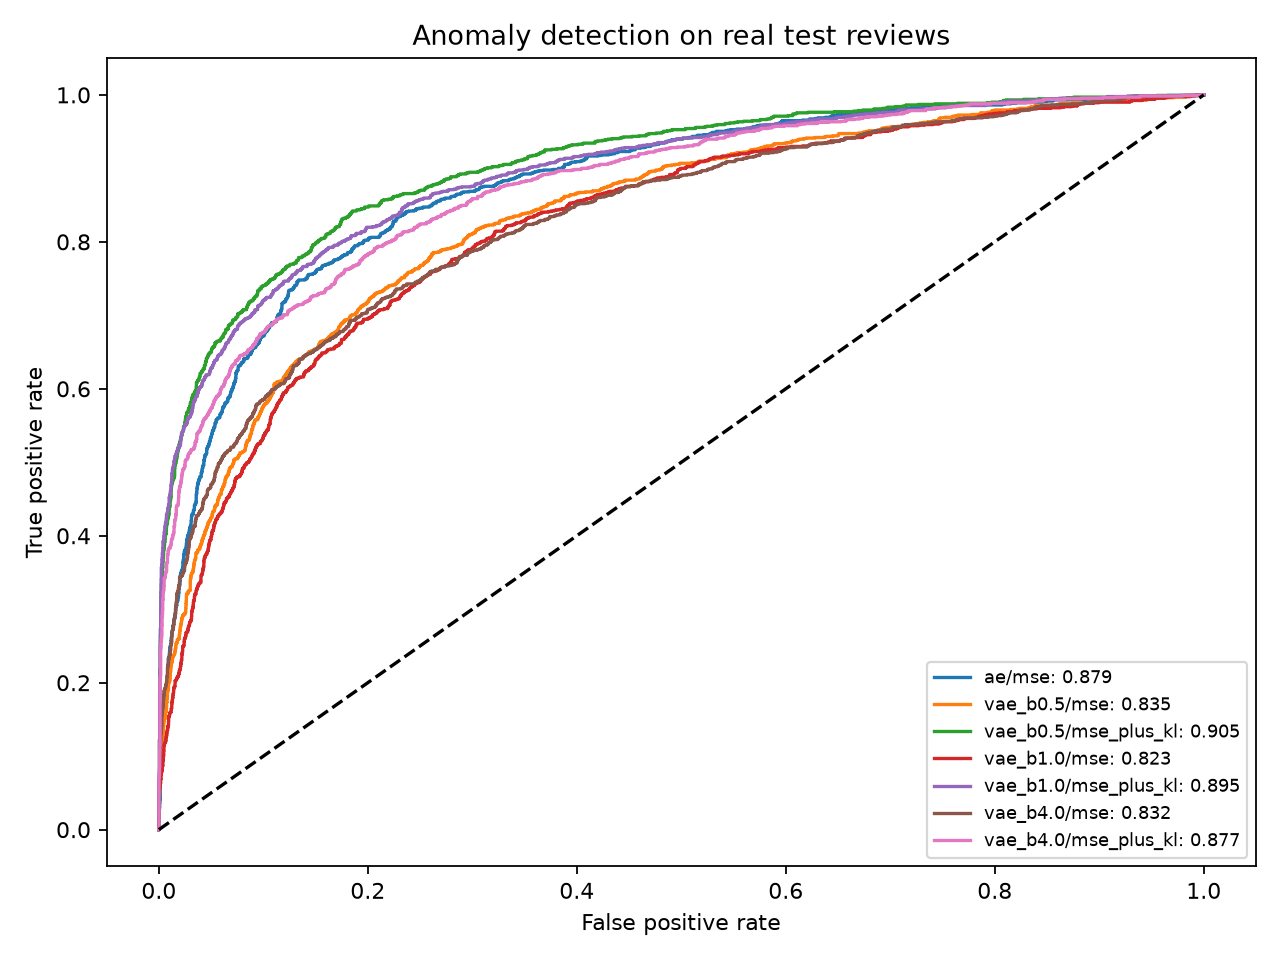

## Score Distributions and Validation Thresholds

Each panel compares normal and anomalous reviews using normalized densities. The vertical line marks the threshold fixed on validation data. Overlap explains both missed anomalies and normal reviews incorrectly flagged as anomalous. Score scales differ across detectors.

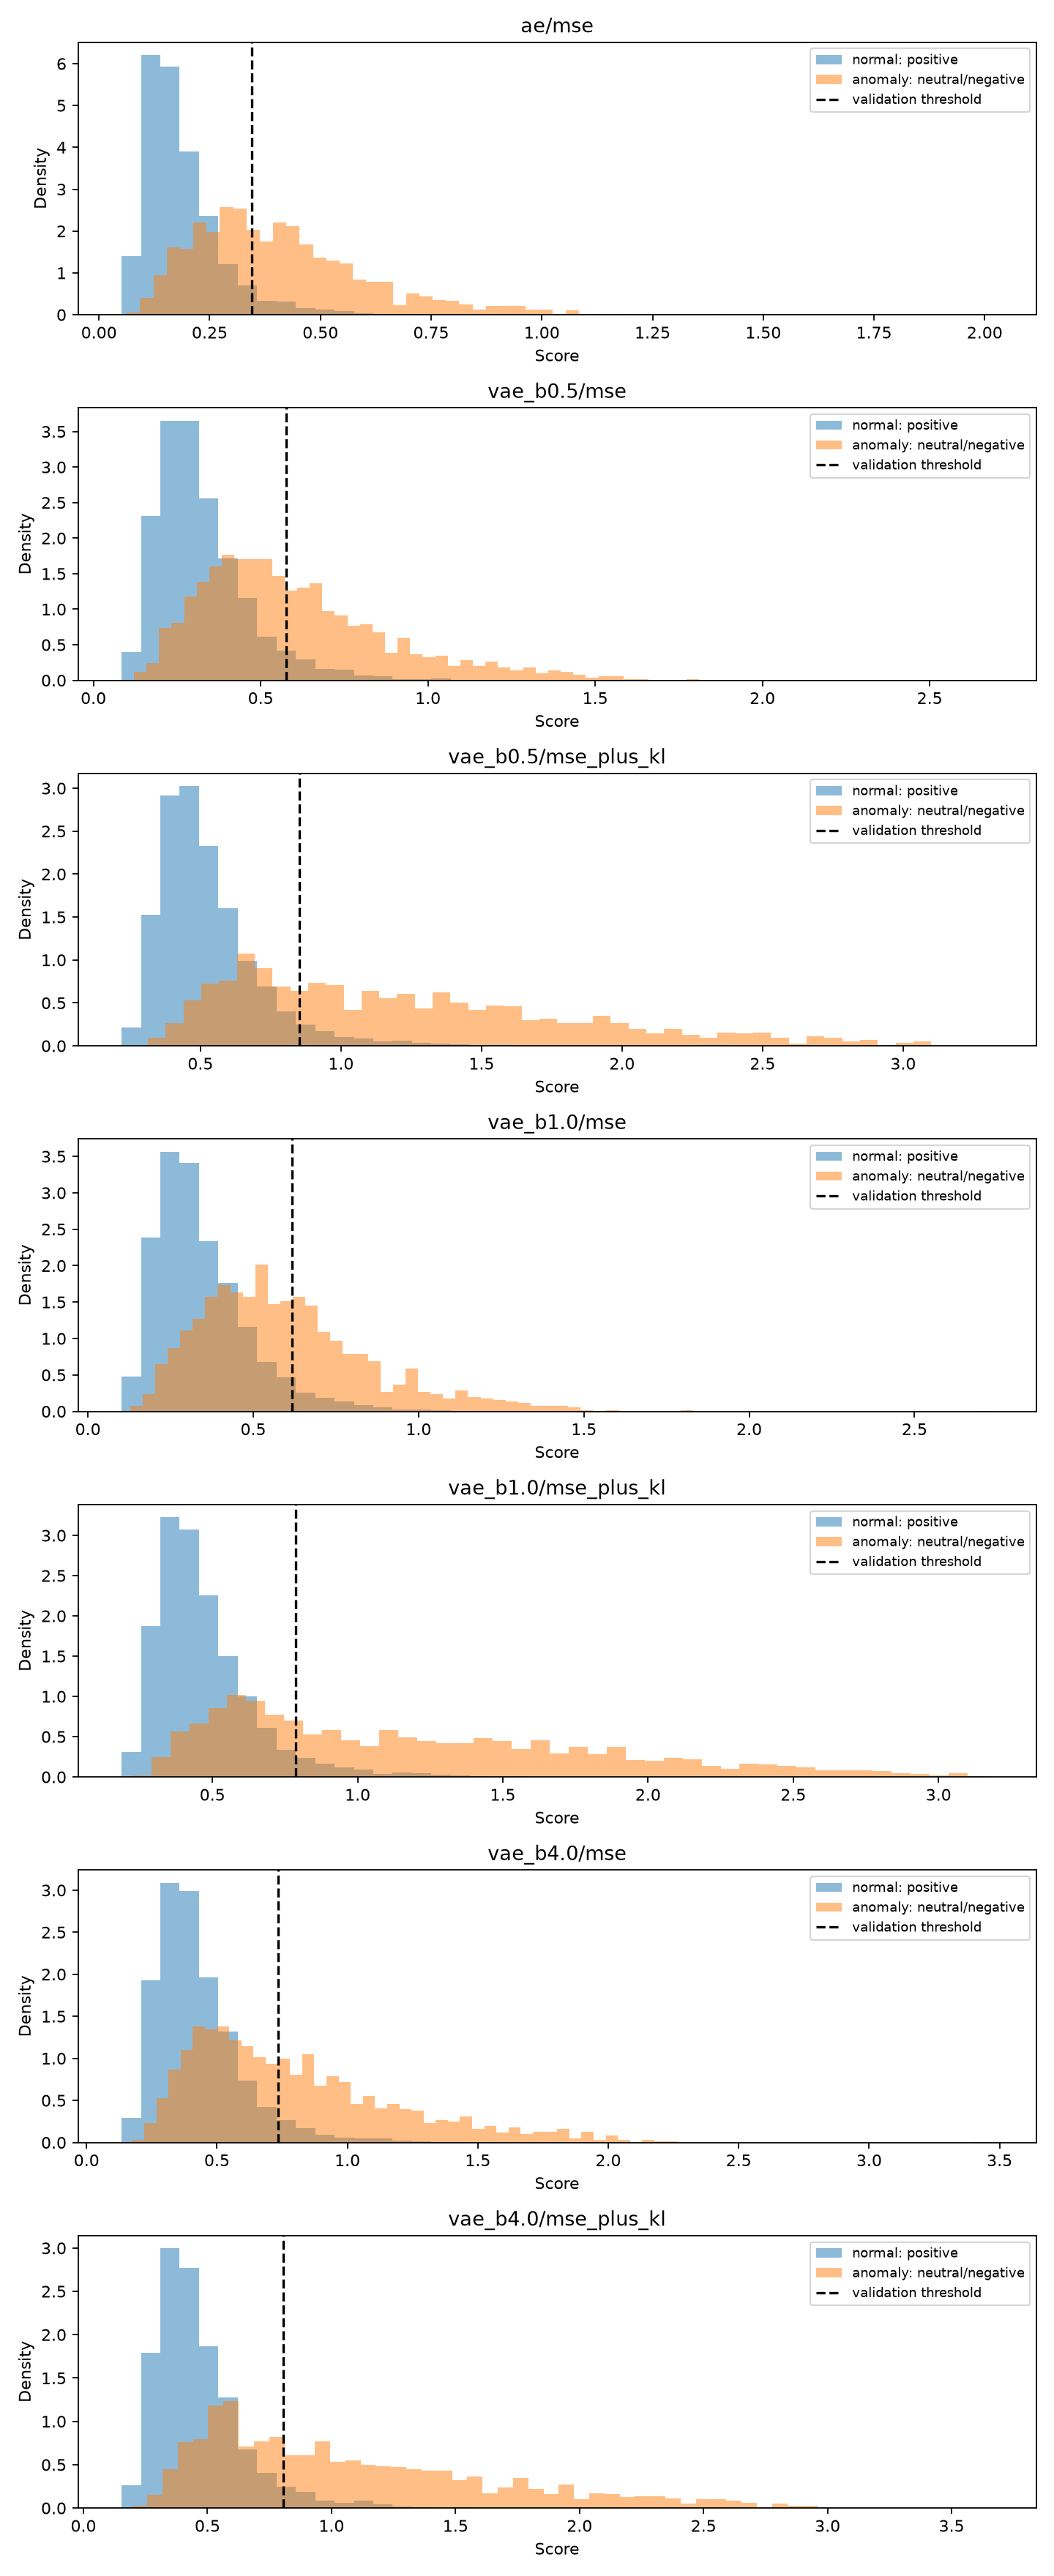

## Confusion Matrices

Rows represent actual classes and columns represent predicted classes, ordered as normal and anomaly. VAE β=0.5 with MSE + KL detects 860 anomalies, misses 450, and produces 267 false positives (5.25% of normal test reviews). AE detects 734 anomalies, misses 576, and produces 293 false positives (5.76%). Calibrating a 5% target on validation data does not guarantee exactly that rate on the test set.

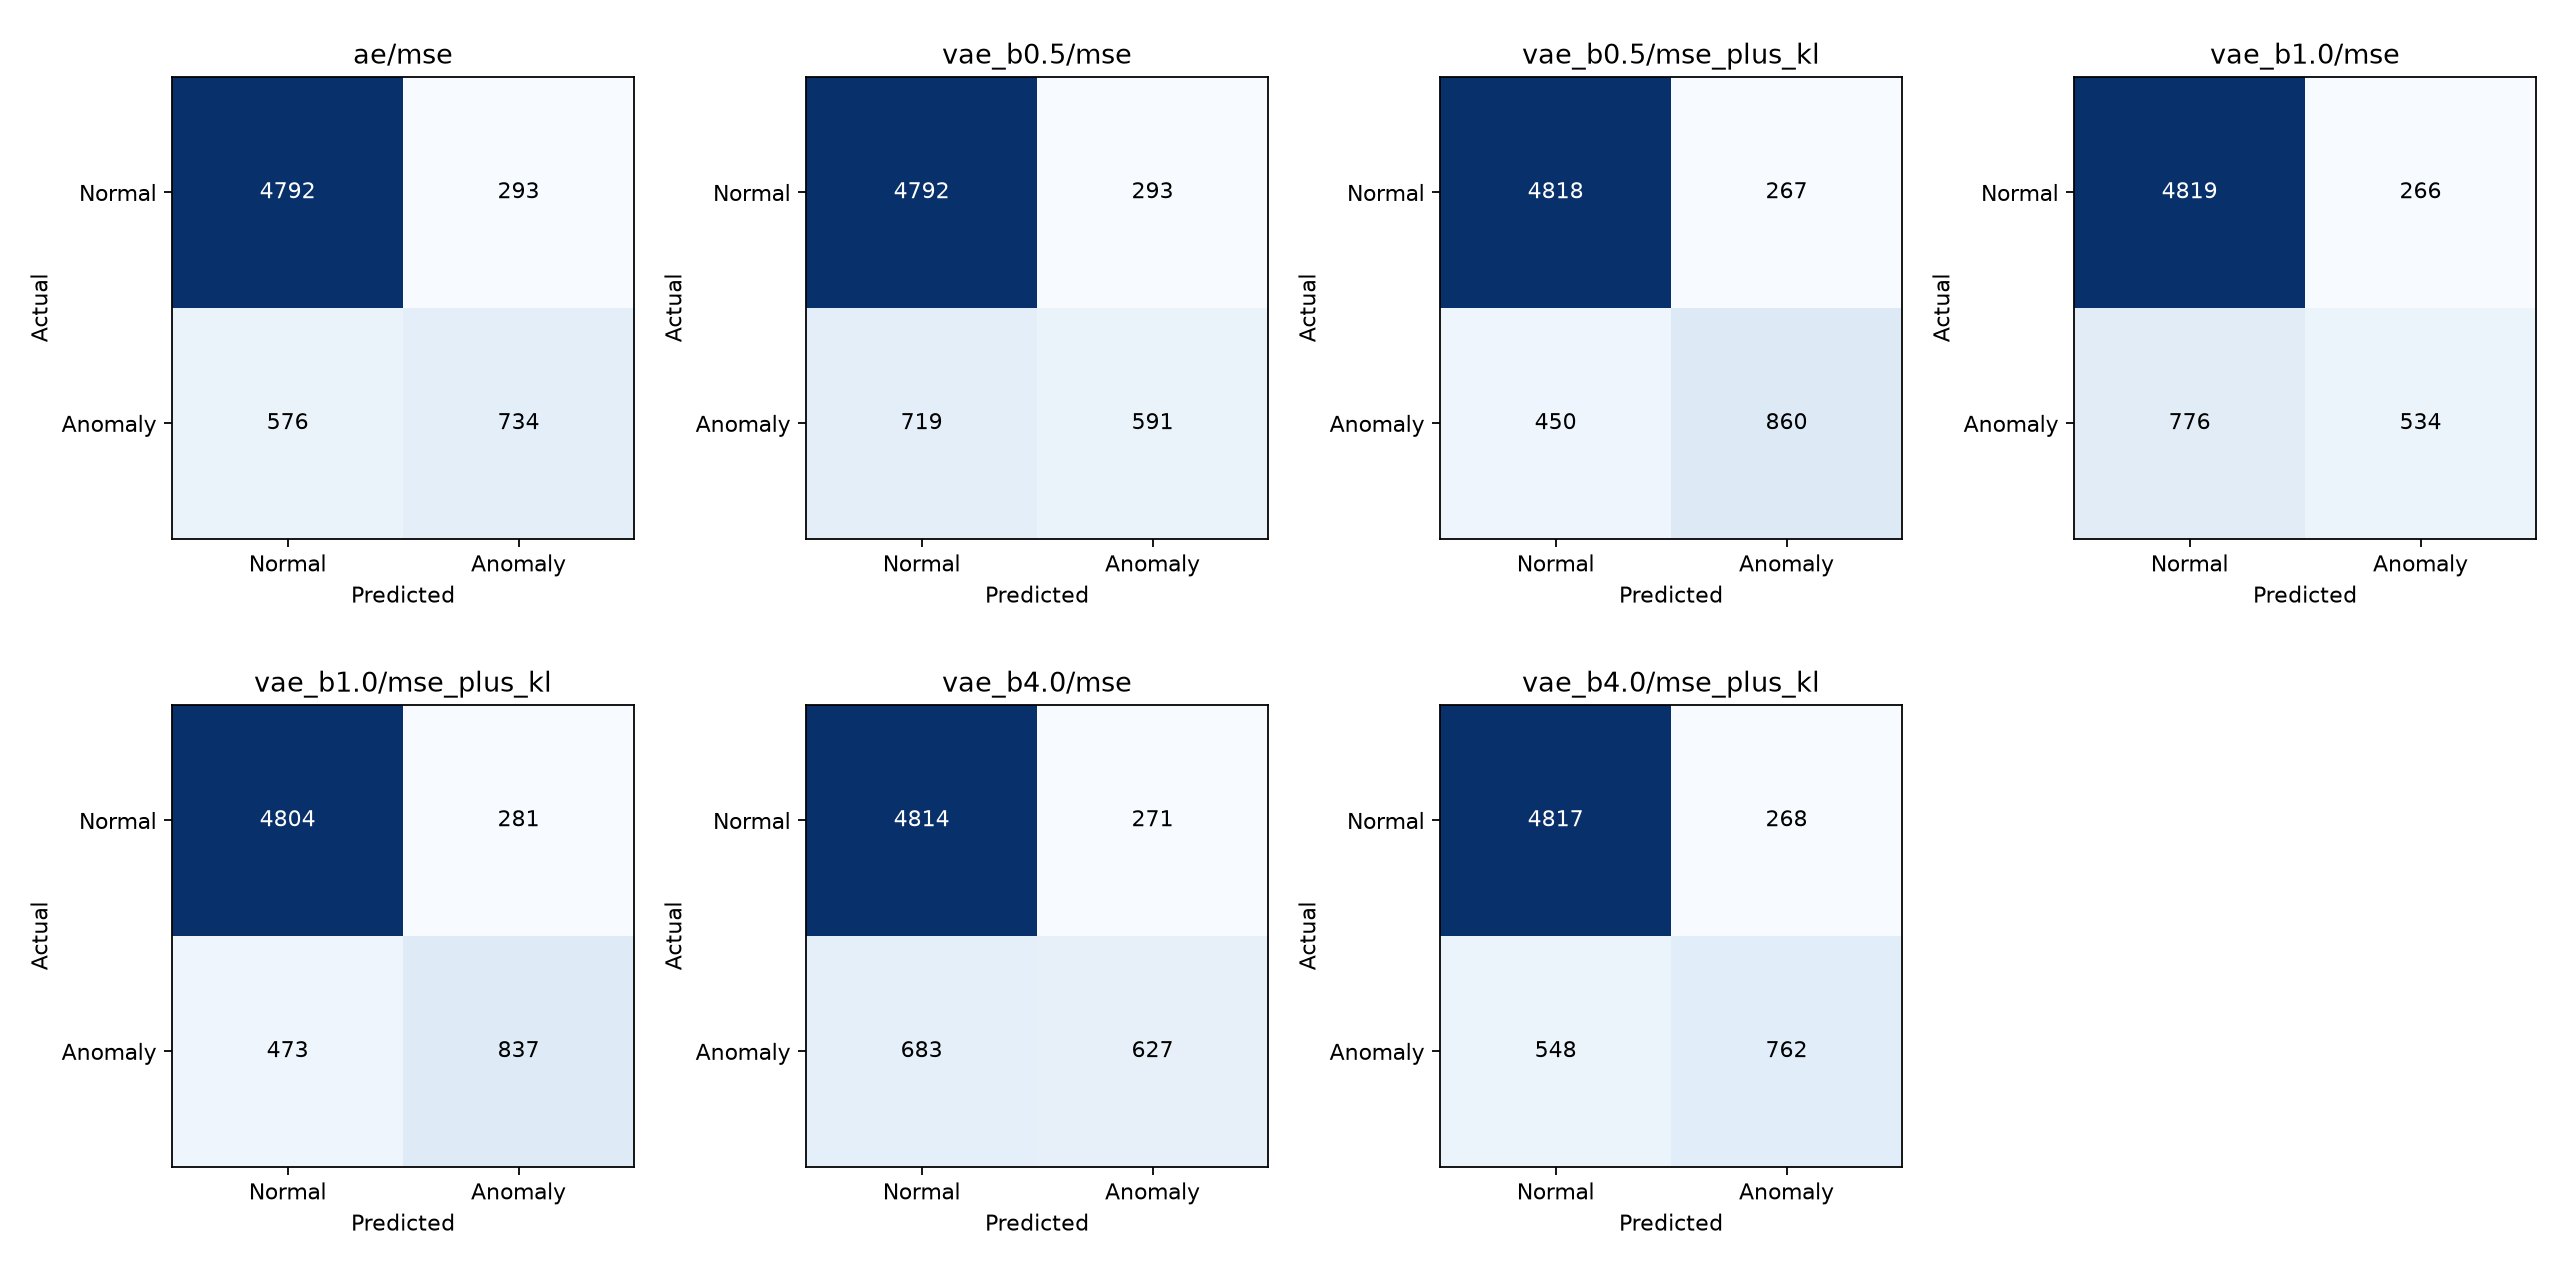

## Supervised Baseline Comparison: W1, W2 and W4

The original W1 corpus was recovered from Kaggle and its SHA256 checksum verified. Original W1 preprocessing reproduced all 42,632 labels and the exact frozen training, validation, and test row order. Original W1 feature extraction and classifier settings were reused, with Random Forest parallelism limited to four workers. Learned transforms were fitted on training data only.

W1 models were selected by **validation sentiment macro-F1**, matching the original W1 ranking criterion. Logistic Regression was selected before interpreting its binary test AUC. These are reproduced W1 results in the recorded environment, rather than recovered historical predictions.

| W1 model | Validation sentiment macro-F1 | Binary test AUC-ROC |
|---|---:|---:|
| majority | 0.2953 | 0.5000 |
| logistic_regression | 0.6251 | 0.9231 |
| random_forest | 0.3016 | 0.8948 |
| multinomial_nb | 0.4318 | 0.8401 |

W2 saved probabilities were aligned with all 6,395 original test identifiers and labels. Both W1 and W2 use `1 - P(positive)` as the anomaly score. All methods share the same binary task: positive is normal; neutral or negative is anomalous.

| Method | Anomaly score | Binary test AUC-ROC |
|---|---|---:|
| W1 Logistic Regression (selected on validation) | 1 − P(positive) | 0.9231 |
| W2 RoBERTa | 1 − P(positive) | 0.9634 |
| W4 AE | MSE | 0.8789 |
| W4 VAE β=0.5 | MSE + KL | 0.9054 |

The supervised classifiers achieve higher AUC in this experiment. They learn directly from sentiment labels, whereas AE/VAE optimize reconstruction of normal embeddings. W4 inputs nevertheless inherit supervision from W2. These are descriptive results; no statistical significance claim is made.

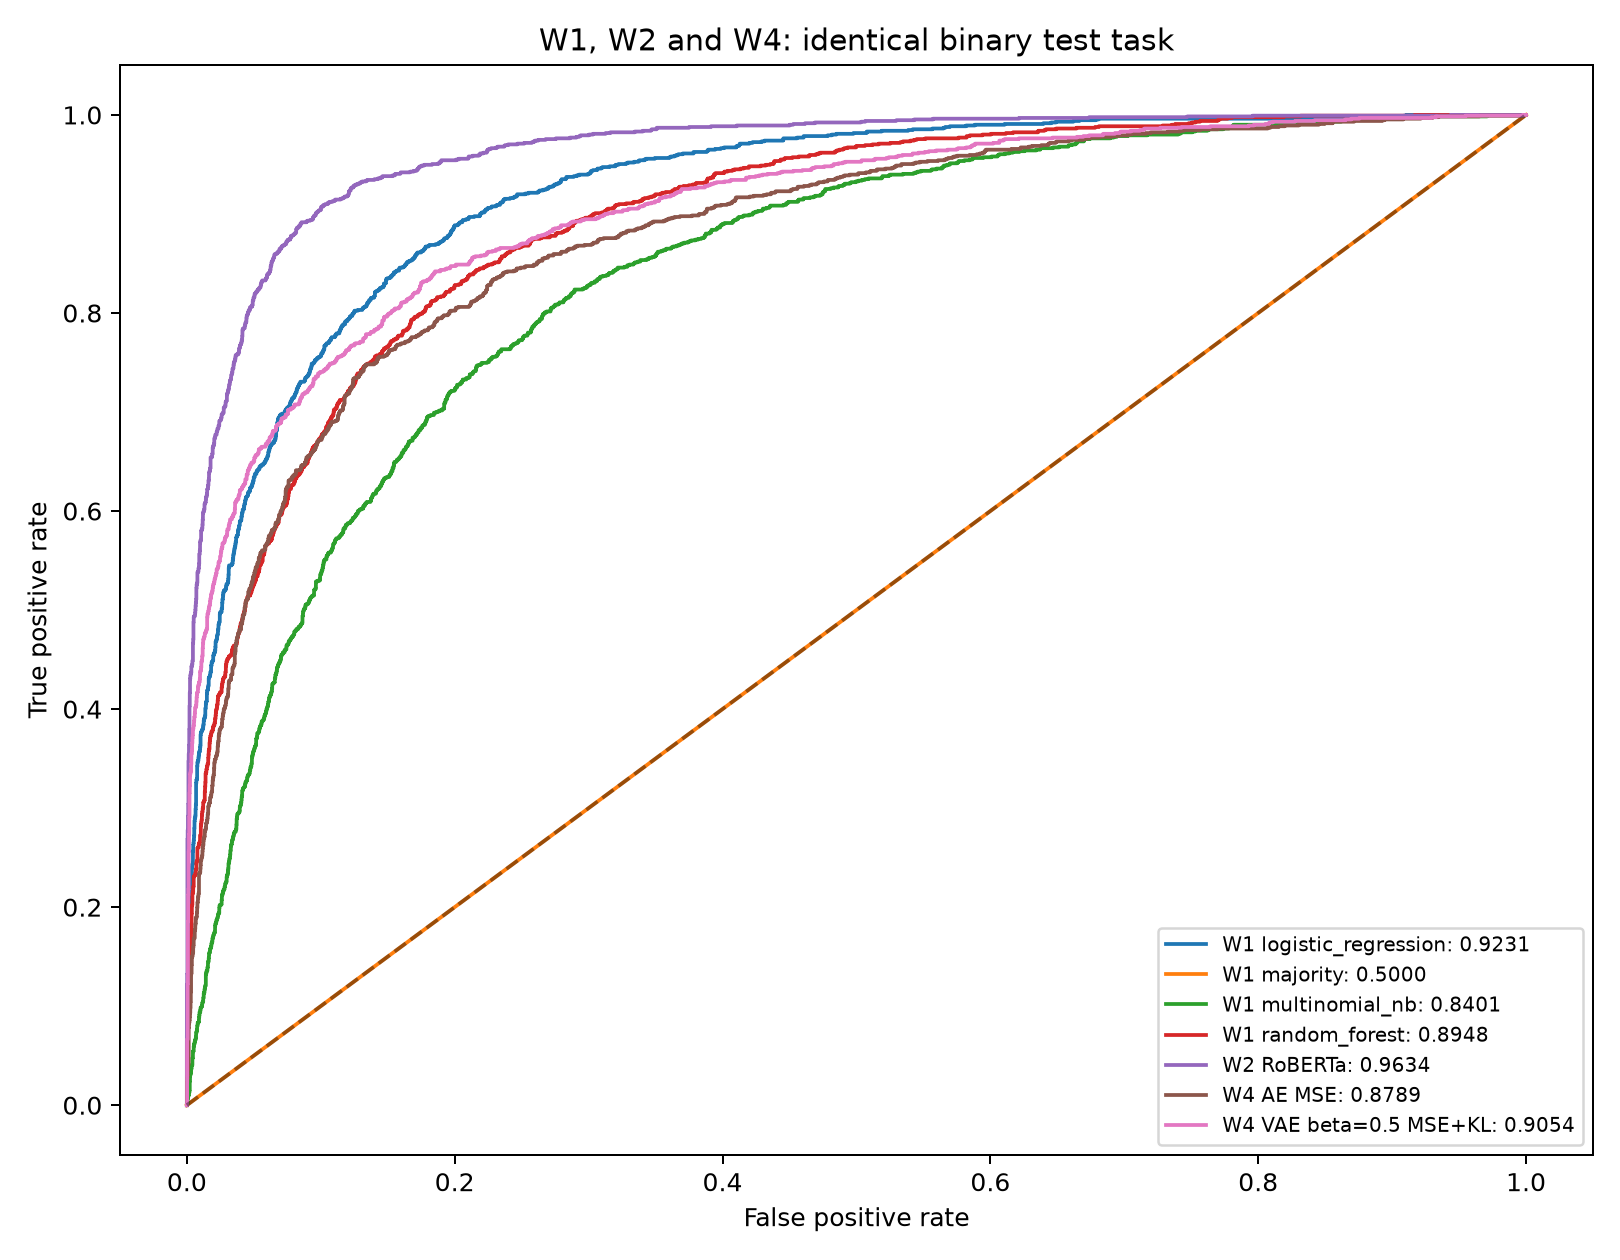

Reproduce from the project root:

```bash
.venv/bin/python src/compare_w1.py
.venv/bin/python src/compare_w2.py
.venv/bin/python src/plot_baseline_comparison.py
```

W1 source is read from the neighboring repository without modifying it. The scripts accept source/prediction path arguments if the repositories are moved. Source hashes, package versions, selection criterion, and scores are stored in `runs/workshop4/evaluation/`.


## Completed Work and Final Integration

**Completed:** reconstruction and anomaly evaluation; nine sample panels; original review excerpts; validation thresholds; ROC curves and confusion matrices; reproduced W1 baselines; W2 probability alignment; binary AUC comparison across all workshops; auditable CSV/JSON outputs and report text.

**Remaining:** integrate this section and its figures into the group PDF and confirm checkpoint training provenance with the team. No W1 or W2 prediction data is still needed for the reported AUC comparison.

**Documented limitations:** the existing AE/VAE training script selects checkpoints using mixed-class validation and compares VAE losses while the KL weight changes. Evaluation preserves the supplied checkpoints. W1 results were reproduced using the recovered corpus and recorded current environment. Anomaly thresholds are calibrated for AE/VAE; the supervised baseline comparison concerns threshold-independent AUC only.


## Optional Reproduction

Select the Python interpreter in `.venv` as the kernel. The first cell locates the project root from either the project directory or `notebooks/`. Evaluation can be rerun without retraining. Uncommenting and running the evaluation command regenerates JSON, CSV, and figure files; the embedded tables and images above remain a snapshot of the documented run.

In [ ]:
from pathlib import Path
import json
import sys
import subprocess

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/evaluate_ae.py").is_file())
metrics_path = ROOT / "runs/workshop4/evaluation/metrics.json"
results = json.loads(metrics_path.read_text())
print("Project:", ROOT)
print("Best VAE by validation MSE:", results["protocol"]["best_vae"])
print("Versions:", results["environment"])

In [ ]:
# Optional: rerun evaluation on the same data and checkpoints.
# subprocess.run([sys.executable, str(ROOT / "src/evaluate_ae.py")], cwd=ROOT, check=True)

In [ ]:
from IPython.display import Image, display

for name in ["reconstruction_panels.png", "reconstruction_by_class.png",
             "anomaly_roc.png", "anomaly_scores.png", "anomaly_confusion_matrices.png"]:
    display(Image(filename=str(ROOT / "notebooks/figures/evaluation" / name)))